# [01-3] 가중치 · 특성중요도 · Feature Engineering — EOL 최종검사 불량 선별

**K-뉴딜 아카데미 스마트팩토리 캡스톤 · 공통 미니 프로젝트 (1~2회차 · 4개 팀 동일 데이터)**

---

## 이 노트북의 학습목표

1. **로지스틱 회귀의 계수(가중치)** 를 읽고 현장 언어로 번역한다.
2. **트리 계열의 특성중요도**와 **순열 중요도**를 비교하고 한계를 안다.
3. **도메인 지식으로 새 변수를 만든다** (feature engineering) — 가장 효과가 큰 작업.
4. **특성선택**(단변량 · 모델기반 · RFE)으로 변수를 줄여도 성능이 유지되는지 확인한다.
5. **PCA**로 차원을 축소하고, 언제 쓰고 언제 쓰면 안 되는지 판단한다.

## 왜 '해석'이 필요한가

성능 좋은 모델을 만들었다고 프로젝트가 끝나지 않습니다. 현장에서는 반드시 묻습니다.

> **"그래서 뭘 고치면 되는데?"**

모델이 "이 설비는 위험합니다(확률 0.82)"라고만 말하면 아무도 움직일 수 없습니다.
**"진동과 필터차압이 함께 올라갔기 때문"** 이라고 말해야 점검 항목이 정해집니다.

이것을 **설명 가능성(explainability)** 이라고 하며, 제조 현장에서는 성능만큼 중요합니다.
이유는 세 가지입니다.

1. **조치로 연결** — 어떤 변수를 바꿔야 하는지 알아야 개선이 된다
2. **신뢰 확보** — 왜 그렇게 판단했는지 설명되어야 현장이 모델을 믿는다
3. **오류 발견** — 이상한 변수가 1등이면 데이터 누출이나 수집 오류일 가능성이 높다

> **중요한 경고**: 특성중요도는 **"모델이 무엇을 많이 참고했는가"** 이지
> **"현실에서 무엇이 원인인가"** 가 아닙니다. 인과관계를 주장하려면
> 실험(공정조건을 바꿔 보기)이나 인과추론 기법이 필요합니다.
> 이 구분을 지키는 것이 신뢰받는 분석가의 조건입니다.

---

## 0. 이 노트북을 사용하는 방법

이 노트북은 **2편(전처리·모델링)** 을 마친 뒤에 실행합니다. 2편에서 만든 전처리·모델 코드를 압축해서 다시 구성하므로 단독 실행도 가능합니다.

**실행 방법**

| 하고 싶은 것 | 방법 |
|---|---|
| 셀 하나 실행 | 셀을 클릭하고 `Shift + Enter` |
| 위에서부터 전체 실행 | 메뉴 `런타임 > 모두 실행` |
| 처음부터 다시 | 메뉴 `런타임 > 런타임 초기화 후 모두 실행` |
| 코드 수정 | 셀 안의 숫자/변수명을 바꾸고 다시 `Shift + Enter` |

**학습 태도에 대한 당부**

- 코드를 **외우려 하지 마세요.** 이 교육의 목표는 "코드를 쓰는 사람"이 아니라
  "데이터로 공정을 판단하는 사람"이 되는 것입니다.
- 각 셀의 주석(`#` 으로 시작하는 줄)과 셀 위의 설명을 먼저 읽고, 출력된 **숫자와 그림이
  현장에서 무슨 뜻인지**를 말로 설명해 보세요.
- 셀 아래의 **생각해 볼 질문**은 발표 자료의 재료가 됩니다. 답을 메모해 두세요.
- 에러가 나면 당황하지 말고 **맨 아랫줄(마지막 Error 문장)** 부터 읽으세요. 대부분
  오타, 변수명 불일치, 셀 실행 순서 문제입니다.

> 이 데이터는 **교육용 합성데이터**입니다. 실제 기업의 설비 상태나 품질 수준을 나타내지
> 않습니다. 따라서 여기서 얻은 수치는 "분석 연습의 결과"이며, 현장 결론으로 그대로
> 인용하면 안 됩니다. 반대로 **분석 절차와 해석 방법**은 실제 현장에서 그대로 쓰입니다.

---

## 1. 환경 준비 (라이브러리 / 한글폰트)

분석은 "도구를 꺼내는 일"에서 시작합니다. 파이썬 자체에는 표 계산이나 그래프 기능이
없고, 필요한 기능을 **라이브러리**(기능 묶음)로 불러와서 씁니다. 이 교육에서 쓰는 4가지는
다음과 같습니다.

| 라이브러리 | 별칭 | 역할 | 현장 비유 |
|---|---|---|---|
| `pandas` | `pd` | 표(엑셀 시트) 형태 데이터 처리 | 엑셀 |
| `numpy` | `np` | 숫자 배열·수학 계산 | 공학용 계산기 |
| `matplotlib` | `plt` | 그래프 그리기 | 모눈종이 + 자 |
| `seaborn` | `sns` | 통계 그래프를 짧은 코드로 | 그래프 템플릿 |
| `scikit-learn` | `sklearn` | 머신러닝 모델·전처리·평가 | 분석 엔진 |

`import A as B` 는 "A라는 도구상자를 가져와서 앞으로 B라는 짧은 이름으로 부르겠다"는 뜻입니다.

**한글 폰트**: 그래프 제목·축이름에 한글을 쓰면 기본 설정에서는 □□□ 로 깨집니다.
아래 셀이 Colab/로컬 환경을 자동으로 판별해 한글 폰트를 설정합니다. (한 번만 실행하면 됩니다.)

In [1]:
# =============================================================================
# [1-1] 라이브러리 불러오기 + 한글 폰트 설정
# =============================================================================
import os
import sys
import glob
import warnings

import numpy as np                 # 수치 계산
import pandas as pd                # 표 데이터 처리
import matplotlib as mpl
import matplotlib.pyplot as plt    # 그래프
import seaborn as sns              # 통계 그래프

# scikit-learn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.feature_selection import (VarianceThreshold, SelectKBest, f_classif,
                                       mutual_info_classif, SelectFromModel, RFECV)
from sklearn.decomposition import PCA
from sklearn.metrics import (confusion_matrix, classification_report, roc_auc_score,
                             recall_score, precision_score, f1_score, accuracy_score)
warnings.filterwarnings("ignore")  # 교육용: 경고 메시지를 숨겨 출력을 깔끔하게 한다

IN_COLAB = "google.colab" in sys.modules   # 지금 Colab에서 실행 중인가?


def setup_korean_font():
    """그래프에 한글이 깨지지 않도록 폰트를 설정한다.

    1) 이미 설치된 한글 폰트가 있으면 그것을 쓴다(로컬 PC/Mac).
    2) 없고 Colab이면 koreanize-matplotlib 패키지를 설치해서 쓴다.
    3) 둘 다 실패하면 영문 폰트를 그대로 쓴다(그래프는 그려지지만 한글이 깨진다).
    """
    from matplotlib import font_manager

    candidates = ["NanumGothic", "NanumBarunGothic", "Malgun Gothic",
                  "AppleGothic", "Noto Sans CJK KR", "Noto Sans KR"]
    installed = {f.name for f in font_manager.fontManager.ttflist}
    for name in candidates:
        if name in installed:
            mpl.rcParams["font.family"] = name
            mpl.rcParams["axes.unicode_minus"] = False   # 음수 기호(-) 깨짐 방지
            return f"설정 완료: {name}"

    if IN_COLAB:
        try:
            import subprocess
            subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                            "koreanize-matplotlib"], check=True)
            import koreanize_matplotlib  # noqa: F401  (import만 해도 폰트가 적용됨)
            mpl.rcParams["axes.unicode_minus"] = False
            return "설정 완료: koreanize-matplotlib (NanumGothic)"
        except Exception as e:      # 네트워크 차단 등
            return f"한글 폰트 설정 실패({e}) - 그래프의 한글이 깨질 수 있습니다"
    return "한글 폰트를 찾지 못했습니다 - 그래프의 한글이 깨질 수 있습니다"


print(setup_korean_font())

# 그래프 기본 모양 / 표 출력 옵션
sns.set_theme(style="whitegrid", font=mpl.rcParams["font.family"][0] if isinstance(mpl.rcParams["font.family"], list) else mpl.rcParams["font.family"])
mpl.rcParams["axes.unicode_minus"] = False
mpl.rcParams["figure.figsize"] = (9, 5)     # 그래프 기본 크기(가로, 세로 인치)
mpl.rcParams["figure.dpi"] = 110            # 해상도
mpl.rcParams["font.size"] = 11

pd.set_option("display.max_columns", 60)    # 표의 열을 생략하지 않고 보여준다
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

print("pandas", pd.__version__, "| numpy", np.__version__, "| Colab:", IN_COLAB)

설정 완료: AppleGothic
pandas 2.2.3 | numpy 2.1.3 | Colab: False


---

## 2. 데이터 불러오기

분석할 파일은 **`K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx`** 입니다. 엑셀 파일의 **`MiniCase_Data`** 시트가 원천데이터입니다.

Colab은 내 PC가 아니라 **구글 클라우드의 임시 컴퓨터**에서 돌아갑니다. 따라서 내 PC에 있는
파일을 Colab이 자동으로 볼 수는 없고, 다음 중 하나로 **파일을 올려줘야** 합니다.

| 방법 | 언제 쓰나 | 특징 |
|---|---|---|
| ① 직접 업로드 | 한 번만 쓸 때 | 아래 셀 실행 → 파일 선택. 런타임이 끊기면 다시 올려야 함 |
| ② 구글 드라이브 마운트 | 수업 내내 쓸 때 (권장) | `drive.mount()` 후 내 드라이브 경로를 그대로 사용 |
| ③ 로컬 주피터 | 내 PC에서 실행할 때 | 노트북과 같은 폴더에 두면 자동 인식 |

아래 셀은 ①②③을 **자동으로 판단**합니다. 흔히 쓰는 경로를 먼저 찾아보고, 못 찾으면
업로드 창을 띄웁니다. 드라이브를 쓰려면 아래 주석 2줄의 `#` 을 지우고 실행하세요.

In [2]:
# =============================================================================
# [2-1] 데이터 파일 찾기 → 읽기
# =============================================================================
# (선택) 구글 드라이브를 쓰려면 아래 2줄의 주석을 해제하고 실행하세요.
# from google.colab import drive
# drive.mount('/content/drive')

DATA_FILE = "K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx"      # 찾을 파일명
NAME_HINT = "MiniCase" # 파일명이 조금 달라도 찾기 위한 키워드

SEARCH_DIRS = [
    os.environ.get("KNEWDEAL_DATA_DIR", ""),   # (강사용) 환경변수로 지정한 폴더
    ".", "..", "../..",                        # 노트북 주변 폴더
    "/content",                                # Colab 업로드 기본 위치
    "/content/drive/MyDrive",
    "/content/drive/MyDrive/K뉴딜",
    "/content/drive/MyDrive/Colab Notebooks",
    os.path.expanduser("~/Downloads"),
]


def find_data_file(file_name, name_hint):
    """후보 폴더를 돌면서 파일을 찾는다. 정확한 파일명 → 키워드 부분일치 순으로 탐색."""
    for d in SEARCH_DIRS:
        if not d:
            continue
        p = os.path.join(d, file_name)
        if os.path.exists(p):
            return p
    for d in SEARCH_DIRS:                       # 파일명이 조금 바뀐 경우 대비
        if not d or not os.path.isdir(d):
            continue
        hits = [p for p in glob.glob(os.path.join(d, "*")) if name_hint in os.path.basename(p)]
        if hits:
            return sorted(hits)[0]
    return None


DATA_PATH = find_data_file(DATA_FILE, NAME_HINT)

if DATA_PATH is None and IN_COLAB:
    print("파일을 찾지 못했습니다. 아래 버튼으로 데이터 파일을 업로드하세요.")
    from google.colab import files
    uploaded = files.upload()               # 파일 선택 창이 열린다
    DATA_PATH = list(uploaded.keys())[0]

if DATA_PATH is None:
    raise FileNotFoundError(
        "데이터 파일을 찾을 수 없습니다.\n"
        f" - 찾는 파일: {DATA_FILE}\n"
        " - 해결: (1) Colab 왼쪽 '파일' 탭에 파일을 끌어다 놓거나\n"
        "         (2) 구글 드라이브를 마운트하고 SEARCH_DIRS에 경로를 추가하세요."
    )

print("데이터 경로:", DATA_PATH)
df_raw = pd.read_excel(DATA_PATH, sheet_name="MiniCase_Data")
print("불러온 데이터 크기:", df_raw.shape, "  (행 수, 열 수)")
df_raw.head(3)

데이터 경로: ../../K-뉴딜_아카데미_1회차_공통MiniCase_미니프로젝트_데이터셋_수정.xlsx


불러온 데이터 크기: (1200, 20)   (행 수, 열 수)


,record_id,timestamp,shift,line_id,product_model,equipment_id,operator_group,torque_nm,pressure_bar,cycle_time_sec,temperature_c,vibration_mm_s,downtime_min,energy_kwh,inspection_result,defect_type,inspection_time_sec,rework_flag,rework_time_min,final_disposition
0,R00001,2026-07-01 21:00:25,야간,L1,P1,M04,G01,31.460,5.980,51.400,35.200,2.700,0,1.000,합격,NaN,37,N,0,합격
1,R00002,2026-07-02 12:12:10,주간,L2,P2,M04,G02,32.370,5.660,50.600,38.600,2.590,0,0.915,합격,NaN,42,N,0,합격
2,R00003,2026-07-03 10:03:12,주간,L1,P1,M03,G03,30.260,5.680,49.400,39.500,2.270,1,1.044,합격,NaN,46,N,0,합격


In [3]:
# 미니케이스 전용: 토크 결측 복원을 위한 '센서로그' 시트도 함께 읽는다
sensor_log = pd.read_excel(DATA_PATH, sheet_name="센서로그")
print("센서로그:", sensor_log.shape)
sensor_log.head(3)

센서로그: (12, 4)


,record_id,timestamp,torque_nm_restored,근거
0,R00845,2026-07-08 15:37:46,30.650,교육용 합성 센서로그: 정상범위 복원 실습
1,R00268,2026-07-20 09:45:48,31.590,교육용 합성 센서로그: 정상범위 복원 실습
2,R00351,2026-07-10 10:38:06,32.010,교육용 합성 센서로그: 정상범위 복원 실습


---

## 3. 2편 내용 압축 재현 — 정제 · 특성 · 분리 · 모델

3편의 주제(해석과 특성공학)에 집중하기 위해, 2편에서 만든 내용을 한 번에 실행합니다.
각 줄이 무엇을 하는지는 2편의 설명을 참고하세요.

특성은 **세트 A(판단 시점에 쓸 수 있는 변수)** 를 기준으로 합니다. 현장에 그대로 적용할 모델을 다듬는 것이 목적이기 때문입니다.

In [4]:
def clean_data(d, sensor_log=None):
    """미니케이스 1단계 정제: 도메인 지식이 필요한 수정만 수행."""
    d = d.copy()
    report = []

    # ① 토크 결측 → 센서로그 복원값으로 채운다 (원본 로그 우선)
    n_missing = int(d["torque_nm"].isna().sum())
    if sensor_log is not None and n_missing > 0:
        restore = sensor_log.set_index("record_id")["torque_nm_restored"]
        fill = d["record_id"].map(restore)
        d["torque_nm"] = d["torque_nm"].fillna(fill)
        report.append(f"토크 결측 {n_missing}건 → 센서로그 복원값으로 대체 "
                      f"(남은 결측 {int(d['torque_nm'].isna().sum())}건)")

    # ② 진동 결측 → '값이 없었다'는 사실을 표시변수로 남기고, 설비별 중앙값으로 대치
    d["vib_missing"] = d["vibration_mm_s"].isna().astype(int)
    before = int(d["vibration_mm_s"].isna().sum())
    d["vibration_mm_s"] = d["vibration_mm_s"].fillna(
        d.groupby("equipment_id")["vibration_mm_s"].transform("median"))
    report.append(f"진동 결측 {before}건 → 설비별 중앙값 대치 + vib_missing 표시변수 추가")

    # ③ defect_type(불량유형)은 구조적 결측이므로 건드리지 않는다
    report.append("defect_type 결측은 구조적 결측(합격품) → 그대로 유지, 특성에서 제외")

    # ④ 시간 변수는 datetime 형으로 변환 (시간순 정렬·시계열 그래프용)
    d["timestamp"] = pd.to_datetime(d["timestamp"])

    return d, report

In [5]:
# =============================================================================
# [3-1] 정제 → 목표변수 → 특성 → 분리 → 파이프라인 (2편 요약)
# =============================================================================
df, clean_report = clean_data(df_raw, sensor_log=sensor_log)
print("정제 완료:", df.shape)

SEED = 42
TIME_COL = "timestamp"
df["target"] = (df['inspection_result'] == '불합격').astype(int)                  # 1 = 불합격(추가확인 대상)

CAT_FEATURES = [c for c in ["shift", "line_id", "product_model", "equipment_id", "operator_group"] if c in df.columns]
NUM_FEATURES = [c for c in [
    "torque_nm", "pressure_bar", "cycle_time_sec", "temperature_c", "vibration_mm_s",
    "downtime_min", "energy_kwh"
] if c in df.columns]
LEAK_COLS = [
    "defect_type", "inspection_time_sec", "rework_flag", "rework_time_min",
    "final_disposition", "record_id"
]


def make_preprocessor(cat_cols, num_cols):
    num_pipe = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("scale", StandardScaler())])
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                         ("onehot", OneHotEncoder(handle_unknown="ignore",
                                                  sparse_output=False))])
    return ColumnTransformer([("num", num_pipe, num_cols), ("cat", cat_pipe, cat_cols)])


def split_data(cat_cols, num_cols, data=None, seed=SEED):
    d = (df if data is None else data).sort_values(TIME_COL).reset_index(drop=True)
    X, y = d[cat_cols + num_cols], d["target"]
    return train_test_split(X, y, test_size=0.25, random_state=seed, stratify=y)


X_train, X_test, y_train, y_test = split_data(CAT_FEATURES, NUM_FEATURES)

logit = Pipeline([("pre", make_preprocessor(CAT_FEATURES, NUM_FEATURES)),
                  ("clf", LogisticRegression(max_iter=2000, class_weight="balanced",
                                             random_state=SEED))]).fit(X_train, y_train)
tree = Pipeline([("pre", make_preprocessor(CAT_FEATURES, NUM_FEATURES)),
                 ("clf", DecisionTreeClassifier(max_depth=4, min_samples_leaf=20,
                                                class_weight="balanced",
                                                random_state=SEED))]).fit(X_train, y_train)
forest = Pipeline([("pre", make_preprocessor(CAT_FEATURES, NUM_FEATURES)),
                   ("clf", RandomForestClassifier(n_estimators=300, max_depth=8,
                                                  min_samples_leaf=5,
                                                  class_weight="balanced",
                                                  random_state=SEED,
                                                  n_jobs=-1))]).fit(X_train, y_train)


def quick_eval(model, name, X_te=None, y_te=None, th=0.5):
    """성능 요약 한 줄 (3편에서 비교용으로 계속 사용)."""
    X_te = X_test if X_te is None else X_te
    y_te = y_test if y_te is None else y_te
    proba = model.predict_proba(X_te)[:, 1]
    pred = (proba >= th).astype(int)
    return {"모델/조건": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred, zero_division=0),
            "F1": f1_score(y_te, pred, zero_division=0),
            "ROC_AUC": roc_auc_score(y_te, proba) if y_te.nunique() == 2 else np.nan,
            "변수수": X_te.shape[1]}


base_scores = [quick_eval(logit, "로지스틱회귀(기본)"),
               quick_eval(tree, "의사결정나무(기본)"),
               quick_eval(forest, "랜덤포레스트(기본)")]
display(pd.DataFrame(base_scores).set_index("모델/조건").round(3))

정제 완료: (1200, 21)


,Accuracy,Precision,Recall,F1,ROC_AUC,변수수
모델/조건,,,,,,
로지스틱회귀(기본),0.650,0.040,0.333,0.071,0.546,12
의사결정나무(기본),0.893,0.222,0.667,0.333,0.805,12
랜덤포레스트(기본),0.960,0.000,0.000,0.000,0.835,12


---

## 4. 로지스틱 회귀의 가중치(계수) 읽기

로지스틱 회귀는 이렇게 계산합니다.

```
z = w₁·x₁ + w₂·x₂ + ... + wₙ·xₙ + b
P(양성) = 1 / (1 + e^(−z))       ← 시그모이드
```

여기서 **w가 가중치(계수)** 입니다. 읽는 법은 세 가지입니다.

### ① 부호 — 방향
- **양수(+)**: 그 변수가 커지면 양성 확률이 **올라간다**
- **음수(−)**: 그 변수가 커지면 양성 확률이 **내려간다**

### ② 크기 — 영향력 (단, 스케일을 맞췄을 때만!)
원래 단위 그대로면 비교가 불가능합니다. 온도(35~42)와 운전시간(0~475)의 계수를
그냥 비교하면 안 됩니다. 우리는 `StandardScaler`로 **표준화**했으므로,
계수는 **"그 변수가 1 표준편차만큼 커질 때 z가 얼마나 변하는가"** 를 뜻합니다.
→ **이제 크기 비교가 가능합니다.**

### ③ 오즈비(odds ratio) — 현장 언어로 번역
`exp(계수)` 를 계산하면 **오즈비**가 됩니다.

> 오즈(odds) = 양성 확률 ÷ 음성 확률. 경마 배당률과 같은 개념.

| exp(계수) | 해석 |
|---|---|
| 2.0 | 1 표준편차 증가하면 양성 오즈가 **2배** |
| 1.0 | 영향 없음 |
| 0.5 | 양성 오즈가 **절반** |

### 계수 해석의 3가지 함정

1. **상관된 변수끼리 계수를 나눠 갖는다.** 같은 정보를 가진 변수 2개를 넣으면
   계수가 반씩 쪼개지거나, 심하면 **부호가 뒤집힙니다.** (다중공선성 — 6절에서 확인)
2. **계수는 "다른 변수가 고정일 때"의 효과**입니다. 현실에서 온도만 변하고 부하는
   그대로인 경우는 드뭅니다.
3. **인과가 아닙니다.** 계수가 크다고 그 변수를 바꾸면 결과가 바뀐다는 보장은 없습니다.

로지스틱 회귀의 계수를 볼 때 이 데이터에서 꼭 확인할 점:

- `product_model_P2` 와 `line_id_L2` 는 **똑같은 정보**입니다(완전 교란). 두 변수를 함께
  넣으면 계수가 서로 나눠 갖거나 부호가 뒤집히는 **불안정 현상**이 생깁니다.
  "계수가 작으니 중요하지 않다"고 읽으면 틀립니다.
- `equipment_id_M03` 의 계수는 양(+)으로 나올 가능성이 높습니다. 다만 이것은
  "M03이 불량을 **만든다**"는 증거가 아니라 "M03에서 불량이 **관찰된다**"는 뜻입니다.

In [6]:
# =============================================================================
# [4-1] 로지스틱 회귀 계수 표 (표준화 계수 + 오즈비)
# =============================================================================
pre_fitted = logit.named_steps["pre"]
feat_names = [n.replace("num__", "").replace("cat__", "")
              for n in pre_fitted.get_feature_names_out()]

coefs = pd.DataFrame({
    "변수": feat_names,
    "계수": logit.named_steps["clf"].coef_[0],
})
coefs["오즈비"] = np.exp(coefs["계수"])
coefs["절대값"] = coefs["계수"].abs()
coefs["방향"] = np.where(coefs["계수"] > 0, "↑ 양성 확률 증가", "↓ 양성 확률 감소")
coefs = coefs.sort_values("절대값", ascending=False).reset_index(drop=True)

display(coefs.drop(columns="절대값").head(20).round(3))
print(f"절편(b) = {logit.named_steps['clf'].intercept_[0]:.3f}")
print("※ 모든 수치형 변수는 표준화되어 있으므로 계수 크기를 서로 비교할 수 있다.")

,변수,계수,오즈비,방향
0,operator_group_G06,-0.992,0.371,↓ 양성 확률 감소
1,equipment_id_M03,0.981,2.667,↑ 양성 확률 증가
2,equipment_id_M01,-0.807,0.446,↓ 양성 확률 감소
3,energy_kwh,-0.745,0.475,↓ 양성 확률 감소
4,operator_group_G02,0.674,1.963,↑ 양성 확률 증가
5,operator_group_G03,-0.593,0.553,↓ 양성 확률 감소
6,operator_group_G05,0.541,1.717,↑ 양성 확률 증가
7,temperature_c,0.372,1.451,↑ 양성 확률 증가
8,equipment_id_M04,-0.320,0.726,↓ 양성 확률 감소
9,cycle_time_sec,0.297,1.346,↑ 양성 확률 증가


절편(b) = -0.597
※ 모든 수치형 변수는 표준화되어 있으므로 계수 크기를 서로 비교할 수 있다.


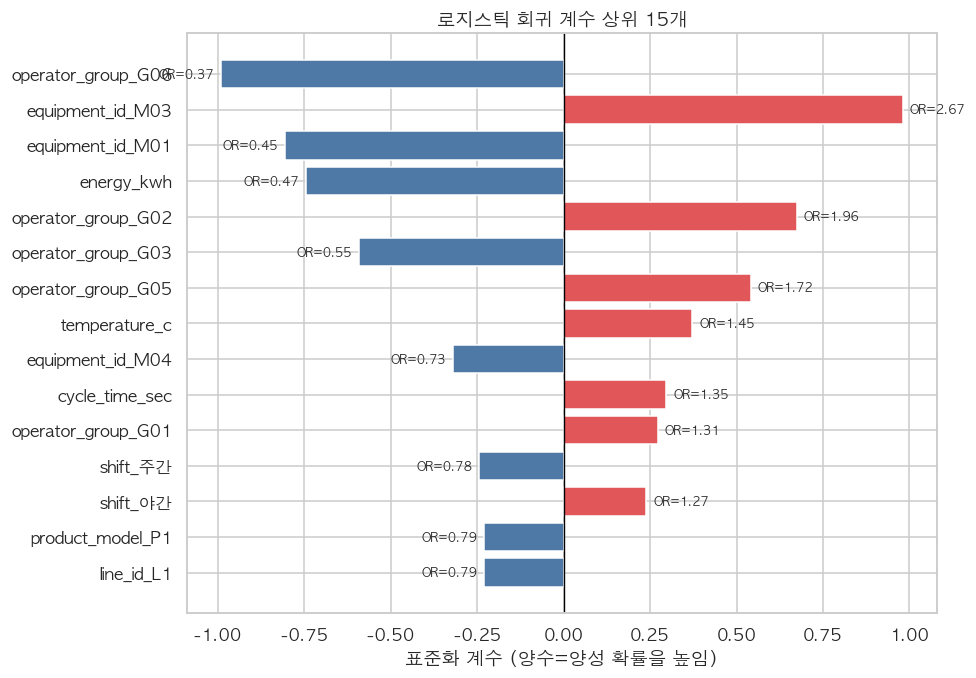

읽는 법 예시:
  'operator_group_G06' 의 계수 -0.992 → 오즈비 0.37
  = 이 변수가 1 표준편차 커지면 양성 오즈가 약 0.37배가 된다
  (단, 다른 변수가 모두 그대로일 때. 그리고 이것은 상관이지 인과가 아니다.)


In [7]:
# =============================================================================
# [4-2] 계수 그래프 (위에서부터 영향이 큰 변수)
# =============================================================================
top = coefs.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * len(top))))
colors = ["#e15759" if v > 0 else "#4e79a7" for v in top["계수"]]
ax.barh(top["변수"], top["계수"], color=colors)
ax.axvline(0, color="black", lw=0.9)
ax.set_xlabel("표준화 계수 (양수=양성 확률을 높임)")
ax.set_title("로지스틱 회귀 계수 상위 15개")
for y_, v, o in zip(range(len(top)), top["계수"], top["오즈비"]):
    ax.text(v + (0.02 if v > 0 else -0.02), y_, f"OR={o:.2f}",
            va="center", ha="left" if v > 0 else "right", fontsize=8)
plt.tight_layout()
plt.show()

print("읽는 법 예시:")
r = coefs.iloc[0]
print(f"  '{r['변수']}' 의 계수 {r['계수']:+.3f} → 오즈비 {r['오즈비']:.2f}")
print(f"  = 이 변수가 1 표준편차 커지면 양성 오즈가 약 {r['오즈비']:.2f}배가 된다")
print("  (단, 다른 변수가 모두 그대로일 때. 그리고 이것은 상관이지 인과가 아니다.)")

---

## 5. 트리 계열의 특성중요도와 순열 중요도

### 5-1. `feature_importances_` (불순도 감소 기반)

트리는 각 분기에서 **불순도(섞임 정도)** 를 줄입니다.
"이 변수를 써서 나눴을 때 불순도가 얼마나 줄었는가"를 전부 합한 것이 특성중요도입니다.
랜덤포레스트는 수백 그루의 평균을 씁니다.

**장점**: 계산이 빠르고, 비선형 관계와 교호작용도 반영됩니다.
**단점 3가지 — 꼭 알아야 합니다.**

1. **고유값이 많은 변수를 과대평가합니다.** 연속형 변수나 범주가 많은 변수는
   나눌 지점이 많아서 우연히 불순도를 줄일 기회가 많습니다.
   (극단적으로, ID를 넣으면 ID가 1등이 됩니다.)
2. **상관된 변수끼리 중요도를 나눠 갖습니다.** 둘 다 중요한데 각각 절반으로 보입니다.
3. **학습 데이터 기준**입니다. 과적합된 부분까지 중요도에 반영됩니다.

### 5-2. 순열 중요도 (Permutation Importance) — 더 믿을 만한 방법

아이디어가 아주 직관적입니다.

> **그 변수의 값만 무작위로 섞어 버린 뒤, 성능이 얼마나 떨어지는지 본다.**

성능이 크게 떨어지면 그 변수는 중요했던 것이고, 거의 안 떨어지면 없어도 되는 변수입니다.

**장점**:
- **모델 종류와 무관**하게 쓸 수 있다 (로지스틱·트리·신경망 모두)
- **평가 데이터**에서 계산하므로 과적합의 영향을 덜 받는다
- "성능이 몇 점 떨어지는가"라는 **직접적인 의미**를 가진다

**단점**: 느리다(여러 번 반복 계산). 상관된 변수가 있으면 둘 다 낮게 나올 수 있다
(하나를 망가뜨려도 다른 하나가 대신하기 때문).

**실무 권장**: 두 가지를 모두 계산해서 **함께** 봅니다. 결과가 크게 다르면
그 이유(상관, 과적합)를 조사합니다.

,변수,중요도,누적비율(%)
0,torque_nm,0.170,17.000
1,energy_kwh,0.157,32.700
2,temperature_c,0.116,44.300
3,cycle_time_sec,0.106,54.900
4,vibration_mm_s,0.088,63.600
5,pressure_bar,0.084,72.100
6,equipment_id_M03,0.034,75.400
7,equipment_id_M02,0.026,78.000
8,downtime_min,0.020,79.900
9,shift_야간,0.020,81.900


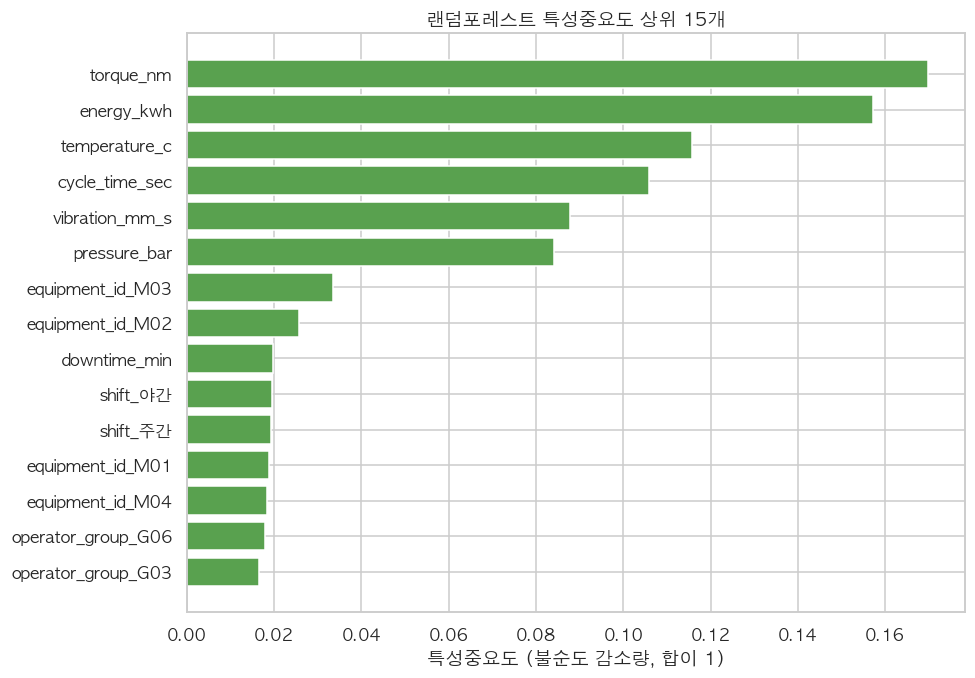

상위 10개 변수가 전체 중요도의 80%를 차지한다 → 센서 축소의 근거가 된다.


In [8]:
# =============================================================================
# [5-1] 랜덤포레스트 특성중요도 (불순도 감소 기반)
# =============================================================================
rf_imp = pd.DataFrame({
    "변수": feat_names,
    "중요도": forest.named_steps["clf"].feature_importances_,
}).sort_values("중요도", ascending=False).reset_index(drop=True)
rf_imp["누적비율(%)"] = (rf_imp["중요도"].cumsum() / rf_imp["중요도"].sum() * 100).round(1)

display(rf_imp.head(15).round(4))

fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * min(15, len(rf_imp)))))
top = rf_imp.head(15)[::-1]
ax.barh(top["변수"], top["중요도"], color="#59a14f")
ax.set_xlabel("특성중요도 (불순도 감소량, 합이 1)")
ax.set_title("랜덤포레스트 특성중요도 상위 15개")
plt.tight_layout()
plt.show()

n80 = int((rf_imp["누적비율(%)"] <= 80).sum()) + 1
print(f"상위 {n80}개 변수가 전체 중요도의 80%를 차지한다 → 센서 축소의 근거가 된다.")

,변수,AUC 감소량,표준편차
0,equipment_id,0.125,0.025
1,torque_nm,0.094,0.023
2,shift,0.070,0.020
3,line_id,0.038,0.015
4,cycle_time_sec,0.023,0.019
5,downtime_min,0.022,0.012
6,product_model,0.020,0.011
7,vibration_mm_s,0.017,0.011
8,operator_group,0.011,0.021
9,energy_kwh,0.006,0.019


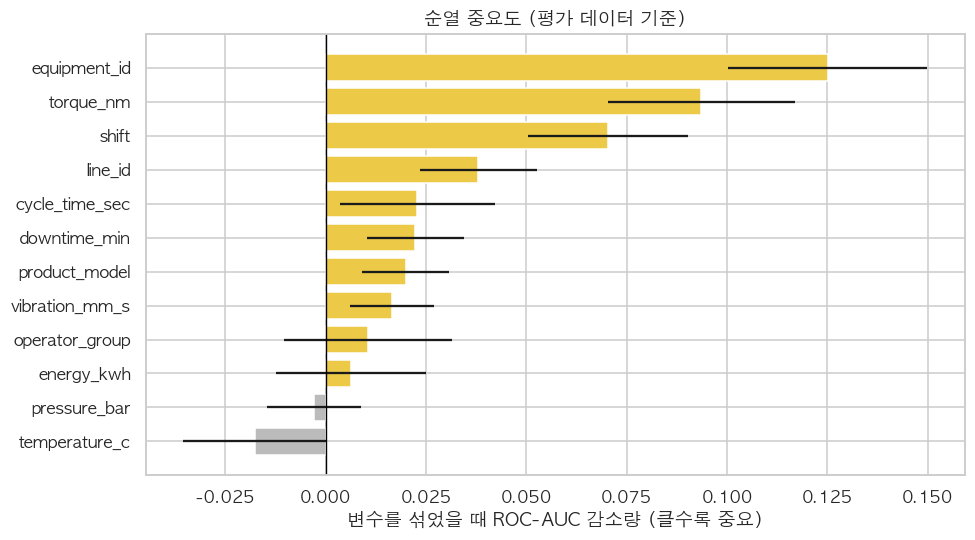

감소량이 0 이하인 변수는 '없어도 되는 변수'일 가능성이 높다.
단, 상관이 높은 변수끼리는 서로 대체하므로 둘 다 낮게 나올 수 있다.


In [9]:
# =============================================================================
# [5-2] 순열 중요도 (평가 데이터에서 계산) - 시간이 조금 걸립니다
# =============================================================================
perm = permutation_importance(forest, X_test, y_test, n_repeats=15,
                              random_state=SEED, scoring="roc_auc", n_jobs=-1)

perm_tbl = pd.DataFrame({
    "변수": X_test.columns,                 # 원본 변수 단위(원핫 이전)
    "AUC 감소량": perm.importances_mean,
    "표준편차": perm.importances_std,
}).sort_values("AUC 감소량", ascending=False).reset_index(drop=True)

display(perm_tbl.round(4))

fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * len(perm_tbl))))
t = perm_tbl[::-1]
ax.barh(t["변수"], t["AUC 감소량"], xerr=t["표준편차"],
        color=["#edc948" if v > 0 else "#bbbbbb" for v in t["AUC 감소량"]])
ax.axvline(0, color="black", lw=0.9)
ax.set_xlabel("변수를 섞었을 때 ROC-AUC 감소량 (클수록 중요)")
ax.set_title("순열 중요도 (평가 데이터 기준)")
plt.tight_layout()
plt.show()

print("감소량이 0 이하인 변수는 '없어도 되는 변수'일 가능성이 높다.")
print("단, 상관이 높은 변수끼리는 서로 대체하므로 둘 다 낮게 나올 수 있다.")

In [10]:
# =============================================================================
# [5-3] 세 가지 해석 방법 비교 (원본 변수 단위로 집계)
# =============================================================================
def to_base(name):
    """원핫인코딩된 이름(shift_Night 등)을 원본 변수명으로 되돌린다."""
    for c in sorted(CAT_FEATURES + NUM_FEATURES, key=len, reverse=True):
        if name == c or name.startswith(c + "_"):
            return c
    return name


coef_base = coefs.assign(기준변수=coefs["변수"].map(to_base)).groupby("기준변수")["절대값"].max()
rf_base = rf_imp.assign(기준변수=rf_imp["변수"].map(to_base)).groupby("기준변수")["중요도"].sum()
perm_base = perm_tbl.set_index("변수")["AUC 감소량"]

cmp3 = pd.DataFrame({
    "로지스틱 |계수|": coef_base,
    "RF 특성중요도": rf_base,
    "순열 중요도": perm_base,
})
for c in cmp3.columns:
    cmp3[c + " 순위"] = cmp3[c].rank(ascending=False)
cmp3 = cmp3.sort_values("순열 중요도", ascending=False)
display(cmp3.round(4))

print("세 방법의 순위가 다른 것은 정상이다. 각각 다른 질문에 답하기 때문이다.")
print("  - 계수      : 다른 변수가 같을 때, 선형적으로 얼마나 기여하나")
print("  - RF 중요도 : 트리가 나눌 때 얼마나 많이 사용했나 (학습 데이터 기준)")
print("  - 순열      : 그 변수를 망가뜨리면 실제 성능이 얼마나 떨어지나 (평가 기준)")
print("\n세 방법 모두에서 상위권인 변수가 '진짜 핵심 변수'다. 보고서에는 이 변수를 쓴다.")

,로지스틱 |계수|,RF 특성중요도,순열 중요도,로지스틱 |계수| 순위,RF 특성중요도 순위,순열 중요도 순위
equipment_id,0.981,0.097,0.125,2.000,5.000,1.000
torque_nm,0.065,0.170,0.094,10.000,1.000,2.000
shift,0.243,0.039,0.070,6.000,9.000,3.000
line_id,0.231,0.022,0.038,7.500,10.000,4.000
cycle_time_sec,0.297,0.106,0.023,5.000,4.000,5.000
downtime_min,0.119,0.020,0.022,9.000,12.000,6.000
product_model,0.231,0.021,0.020,7.500,11.000,7.000
vibration_mm_s,0.025,0.088,0.017,12.000,6.000,8.000
operator_group,0.992,0.081,0.011,1.000,8.000,9.000
energy_kwh,0.745,0.157,0.006,3.000,2.000,10.000


세 방법의 순위가 다른 것은 정상이다. 각각 다른 질문에 답하기 때문이다.
  - 계수      : 다른 변수가 같을 때, 선형적으로 얼마나 기여하나
  - RF 중요도 : 트리가 나눌 때 얼마나 많이 사용했나 (학습 데이터 기준)
  - 순열      : 그 변수를 망가뜨리면 실제 성능이 얼마나 떨어지나 (평가 기준)

세 방법 모두에서 상위권인 변수가 '진짜 핵심 변수'다. 보고서에는 이 변수를 쓴다.


> **다음 단계: SHAP**
> 실무에서는 **SHAP(SHapley Additive exPlanations)** 을 많이 씁니다.
> 게임이론에서 "여러 사람이 협력해 만든 성과를 공정하게 나누는 방법"을 가져와,
> **기록 하나하나에 대해 각 변수가 예측값을 얼마나 밀었는지**를 계산합니다.
> 전체 중요도뿐 아니라 **"이 설비가 위험하다고 판단한 이유"** 를 개별로 설명할 수 있어
> 현장 대시보드에 적합합니다.
>
> ```python
> !pip install -q shap
> import shap
> explainer = shap.TreeExplainer(forest.named_steps["clf"])
> shap_values = explainer.shap_values(forest.named_steps["pre"].transform(X_test))
> shap.summary_plot(shap_values[..., 1], feature_names=feat_names)
> ```
> 7~9회차(분석방법 설계)에서 다룰 수 있는 확장 주제입니다.

---

## 6. Feature Engineering — 변수를 '더 잘' 만들기

### 왜 이것이 가장 중요한 작업인가

실무에서 성능을 가장 크게 끌어올리는 것은 **모델 교체가 아니라 특성공학**입니다.

| 작업 | 전형적인 성능 향상 | 필요한 것 |
|---|---|---|
| 모델을 바꾼다 (RF → XGBoost 등) | 작다 | 코드 몇 줄 |
| 하이퍼파라미터 튜닝 | 작다 | 계산 시간 |
| **좋은 변수를 만든다** | **크다** | **도메인 지식** |
| 데이터를 더 모은다 | 매우 크다 | 시간·비용 |

**특성공학은 "현장 지식을 숫자로 번역하는 일"** 입니다. 그래서 파이썬을 잘하는 사람보다
**공정을 아는 사람**이 더 잘합니다. 여러분의 강점이 발휘되는 지점입니다.

### 특성공학의 5가지 기본 패턴

| 패턴 | 예시 | 왜 효과적인가 |
|---|---|---|
| **비율/정규화** | 전류 ÷ 부하율, 전력 ÷ 생산량 | 규모 효과를 제거해 '효율'을 본다 |
| **차이/편차** | 토출온도 − 주변온도, 실제 − 계획 | 기준 대비 이탈을 직접 표현 |
| **플래그(0/1)** | 규격 이탈 여부, 재고 부족 여부 | 현장의 판단 기준을 모델에 알려 준다 |
| **교호작용(곱)** | 야간 × M03, 혼잡도 × 거리 | "둘이 겹칠 때만 위험"을 선형모델도 쓸 수 있게 |
| **시간 변환/지연** | 시각의 sin·cos, 직전 구간 값 | 주기성과 과거 정보를 표현 |

### 주의: 파생변수가 누출을 만들 수 있습니다

파생변수를 만들 때 **원재료가 되는 변수가 판단 시점에 존재하는지** 반드시 확인하세요.
"실제 리드타임 대비 대기 비율" 같은 변수는 계산은 되지만, 로트가 끝나야 알 수 있습니다.

### 이 데이터에서 만들 파생변수

미니케이스의 핵심 파생변수는 **"현장 규격과 현장 경험을 변수로 바꾸는 것"** 입니다.

| 만들 변수 | 계산식 | 왜 만드나 |
|---|---|---|
| `torque_out_of_spec` | 토크 < 27 또는 > 33 이면 1 | 현장 관리규격을 모델에 알려준다 |
| `torque_center_dist` | \|토크 − 30\| | 규격 중심에서 얼마나 멀어졌는가(정도) |
| `night_m03` | 야간 AND M03 이면 1 | 1회차에서 발견한 위험조건(교호작용)을 명시한다 |
| `temp_high` | 설비온도 ≥ 상위 25% | 온도 수준을 구간으로 단순화 |
| `vib_per_cycle` | 진동 / 사이클타임 | 처리속도 대비 진동 수준 |

특히 `night_m03`은 **교호작용(interaction)** 의 예입니다. 선형모델은 "야간이면 +a,
M03이면 +b" 처럼 각 효과를 **따로** 더할 뿐이어서, "야간 **그리고** M03일 때만 특별히
위험하다"는 관계를 스스로 표현할 수 없습니다. 사람이 미리 곱해서 넣어 주면 선형모델도
그 관계를 쓸 수 있습니다. (트리 계열은 분기를 겹쳐서 스스로 어느 정도 표현합니다.)

In [11]:
def add_features(d):
    """미니케이스 도메인 파생변수 추가."""
    d = d.copy()

    # ① 공정규격 이탈 여부 (현장 관리기준 27~33 N·m)
    d["torque_out_of_spec"] = (((d["torque_nm"] < 27) | (d["torque_nm"] > 33))
                               .astype(float))
    # 토크가 결측인 행은 '이탈 여부 모름'이므로 NaN으로 되돌린다(함부로 0으로 두지 않는다)
    d.loc[d["torque_nm"].isna(), "torque_out_of_spec"] = np.nan

    # ② 규격 중심(30)에서 떨어진 거리 - 이탈의 '정도'를 숫자로
    d["torque_center_dist"] = (d["torque_nm"] - 30).abs()

    # ③ 1회차 EDA에서 발견한 위험조건: 야간 AND M03 (교호작용)
    d["night_m03"] = ((d["shift"] == "야간") & (d["equipment_id"] == "M03")).astype(int)

    # ④ 설비온도 상위 구간 플래그 (상위 25%를 '높음'으로 본다)
    temp_q75 = d["temperature_c"].quantile(0.75)
    d["temp_high"] = (d["temperature_c"] >= temp_q75).astype(int)

    # ⑤ 처리속도 대비 진동 수준 (단위를 맞춘 비율 변수)
    d["vib_per_cycle"] = d["vibration_mm_s"] / d["cycle_time_sec"]

    return d

In [12]:
# =============================================================================
# [6-1] 파생변수 생성 + 성능 비교 (기존 vs 파생변수 추가)
# =============================================================================
df_fe = add_features(df)

NEW_NUM = [c for c in ["torque_center_dist", "vib_per_cycle"] + ["torque_out_of_spec", "night_m03", "temp_high"] if c in df_fe.columns]
NEW_CAT = [c for c in [] if c in df_fe.columns]

CAT_FE = CAT_FEATURES + NEW_CAT
NUM_FE = NUM_FEATURES + NEW_NUM

print(f"기존 특성 {len(CAT_FEATURES) + len(NUM_FEATURES)}개 "
      f"→ 파생 추가 후 {len(CAT_FE) + len(NUM_FE)}개")
print("추가된 변수:", NEW_NUM + NEW_CAT)
display(df_fe[NEW_NUM].describe().T.round(3))

기존 특성 12개 → 파생 추가 후 17개
추가된 변수: ['torque_center_dist', 'vib_per_cycle', 'torque_out_of_spec', 'night_m03', 'temp_high']


,count,mean,std,min,25%,50%,75%,max
torque_center_dist,"1,200.000",1.592,1.008,0.010,0.780,1.545,2.280,4.200
vib_per_cycle,"1,200.000",0.038,0.008,0.022,0.031,0.038,0.044,0.056
torque_out_of_spec,"1,200.000",0.083,0.277,0.000,0.000,0.000,0.000,1.000
night_m03,"1,200.000",0.117,0.321,0.000,0.000,0.000,0.000,1.000
temp_high,"1,200.000",0.259,0.438,0.000,0.000,0.000,1.000,1.000


,Accuracy,Precision,Recall,F1,ROC_AUC,변수수
모델/조건,,,,,,
로지스틱 · 기존변수,0.650,0.040,0.333,0.071,0.546,12
로지스틱 · 파생변수 추가,0.823,0.127,0.583,0.209,0.817,17
랜덤포레스트 · 기존변수,0.960,0.000,0.000,0.000,0.835,12
랜덤포레스트 · 파생변수 추가,0.963,1.000,0.083,0.154,0.906,17


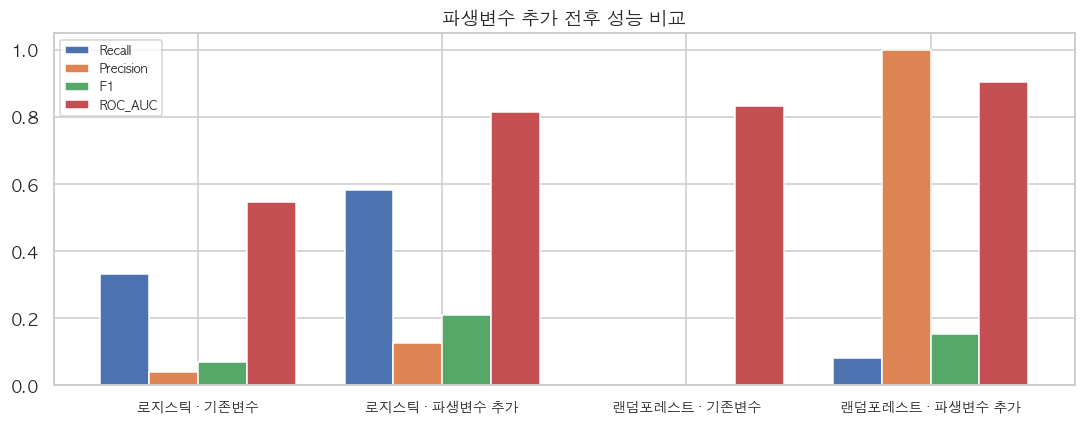

랜덤포레스트 AUC 변화: +0.071
※ 성능이 거의 그대로여도 실패가 아니다. 파생변수가 '해석을 쉽게' 만들었다면 가치가 있다.
※ 선형모델(로지스틱)에서 개선 폭이 더 큰 경우가 많다. 트리는 조합을 스스로 찾기 때문이다.


In [13]:
# =============================================================================
# [6-2] 파생변수가 성능을 올렸는가?
# =============================================================================
Xf_tr, Xf_te, yf_tr, yf_te = split_data(CAT_FE, NUM_FE, data=df_fe)

forest_fe = Pipeline([
    ("pre", make_preprocessor(CAT_FE, NUM_FE)),
    ("clf", RandomForestClassifier(n_estimators=300, max_depth=8, min_samples_leaf=5,
                                   class_weight="balanced", random_state=SEED, n_jobs=-1)),
]).fit(Xf_tr, yf_tr)

logit_fe = Pipeline([
    ("pre", make_preprocessor(CAT_FE, NUM_FE)),
    ("clf", LogisticRegression(max_iter=3000, class_weight="balanced",
                               random_state=SEED)),
]).fit(Xf_tr, yf_tr)

fe_scores = [
    quick_eval(logit, "로지스틱 · 기존변수"),
    quick_eval(logit_fe, "로지스틱 · 파생변수 추가", X_te=Xf_te, y_te=yf_te),
    quick_eval(forest, "랜덤포레스트 · 기존변수"),
    quick_eval(forest_fe, "랜덤포레스트 · 파생변수 추가", X_te=Xf_te, y_te=yf_te),
]
fe_tbl = pd.DataFrame(fe_scores).set_index("모델/조건")
display(fe_tbl.round(3))

fig, ax = plt.subplots(figsize=(10, 4))
idx = np.arange(4)
for i, m in enumerate(["Recall", "Precision", "F1", "ROC_AUC"]):
    ax.bar(idx + i * 0.2, fe_tbl[m], width=0.2, label=m)
ax.set_xticks(idx + 0.3)
ax.set_xticklabels(fe_tbl.index, fontsize=9)
ax.set_ylim(0, 1.05)
ax.set_title("파생변수 추가 전후 성능 비교")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

d_auc = fe_tbl.loc["랜덤포레스트 · 파생변수 추가", "ROC_AUC"] - \
        fe_tbl.loc["랜덤포레스트 · 기존변수", "ROC_AUC"]
print(f"랜덤포레스트 AUC 변화: {d_auc:+.3f}")
print("※ 성능이 거의 그대로여도 실패가 아니다. 파생변수가 '해석을 쉽게' 만들었다면 가치가 있다.")
print("※ 선형모델(로지스틱)에서 개선 폭이 더 큰 경우가 많다. 트리는 조합을 스스로 찾기 때문이다.")

,변수,중요도,구분
0,torque_center_dist,0.138,파생
1,energy_kwh,0.104,기존
2,torque_nm,0.092,기존
3,torque_out_of_spec,0.083,파생
4,temperature_c,0.072,기존
5,cycle_time_sec,0.067,기존
6,night_m03,0.062,파생
7,vibration_mm_s,0.059,기존
8,vib_per_cycle,0.054,파생
9,pressure_bar,0.054,기존


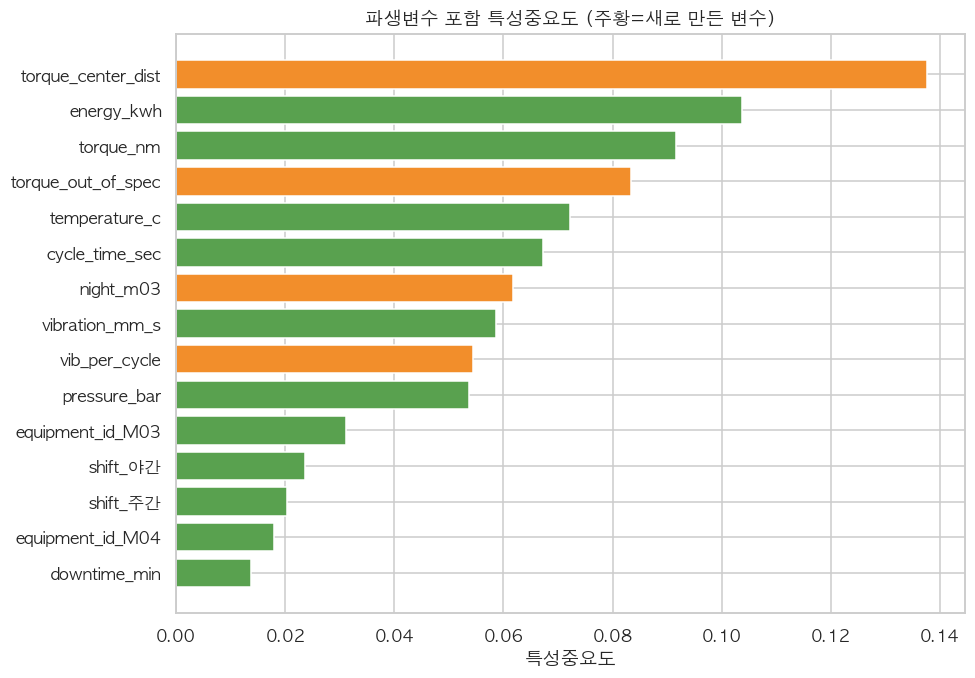

파생변수가 차지하는 중요도 비중: 35.1%


In [14]:
# =============================================================================
# [6-3] 파생변수의 중요도 확인 - 새로 만든 변수가 실제로 쓰이는가?
# =============================================================================
fe_names = [n.replace("num__", "").replace("cat__", "")
            for n in forest_fe.named_steps["pre"].get_feature_names_out()]
fe_imp = pd.DataFrame({
    "변수": fe_names,
    "중요도": forest_fe.named_steps["clf"].feature_importances_,
}).sort_values("중요도", ascending=False).reset_index(drop=True)
fe_imp["구분"] = np.where(fe_imp["변수"].str.split("_").str[0].isin(
    [c.split("_")[0] for c in (NEW_NUM + NEW_CAT)]), "파생", "기존")

# 더 정확한 구분: 새로 만든 이름이 포함되어 있는지로 판단
def is_new(name):
    return any(name == c or name.startswith(c + "_") for c in (NEW_NUM + NEW_CAT))


fe_imp["구분"] = np.where(fe_imp["변수"].map(is_new), "파생", "기존")
display(fe_imp.head(15).round(4))

top = fe_imp.head(15)[::-1]
fig, ax = plt.subplots(figsize=(9, max(4, 0.42 * len(top))))
ax.barh(top["변수"], top["중요도"],
        color=["#f28e2b" if g == "파생" else "#59a14f" for g in top["구분"]])
ax.set_title("파생변수 포함 특성중요도 (주황=새로 만든 변수)")
ax.set_xlabel("특성중요도")
plt.tight_layout()
plt.show()

share = fe_imp[fe_imp["구분"] == "파생"]["중요도"].sum() / fe_imp["중요도"].sum() * 100
print(f"파생변수가 차지하는 중요도 비중: {share:.1f}%")

---

## 7. 다중공선성 — 같은 말을 하는 변수들

**다중공선성(multicollinearity)** 은 입력변수끼리 강하게 상관되어 있는 상태입니다.
예를 들어 "부하율"과 "모터전류"는 거의 같은 이야기를 합니다.

### 왜 문제인가

| 영향 | 설명 |
|---|---|
| **계수 불안정** | 데이터가 조금만 바뀌어도 계수가 크게 흔들리고, **부호가 뒤집히기도** 한다 |
| **해석 왜곡** | "둘 다 중요하지 않다"처럼 보이거나 한쪽이 모든 공을 가져간다 |
| 예측 성능 | **의외로 큰 영향 없음** (예측만 할 거면 큰 문제가 아니다) |

→ **예측만 할 것인가, 설명도 할 것인가**에 따라 대응이 달라집니다.
우리는 현장에 설명해야 하므로 **정리하는 쪽**을 택합니다.

### 확인 방법 2가지

1. **상관 히트맵**: |r| > 0.8 인 쌍을 찾는다 (가장 간단)
2. **VIF(분산팽창계수)**: 한 변수를 나머지 변수들로 회귀했을 때의 R²로 계산
   `VIF = 1 / (1 − R²)`
   - VIF < 5 : 양호
   - 5 ~ 10 : 주의
   - **> 10 : 심각** (거의 같은 정보)

### 대응 방법
- 둘 중 **측정하기 쉽고 해석이 명확한 쪽**만 남긴다 (가장 흔한 선택)
- 둘을 합쳐 새 변수를 만든다 (예: 전류 ÷ 부하율)
- **PCA**로 묶는다 (9절) — 해석은 어려워진다
- 규제(Ridge/Lasso)를 쓴다 — 계수를 안정화한다

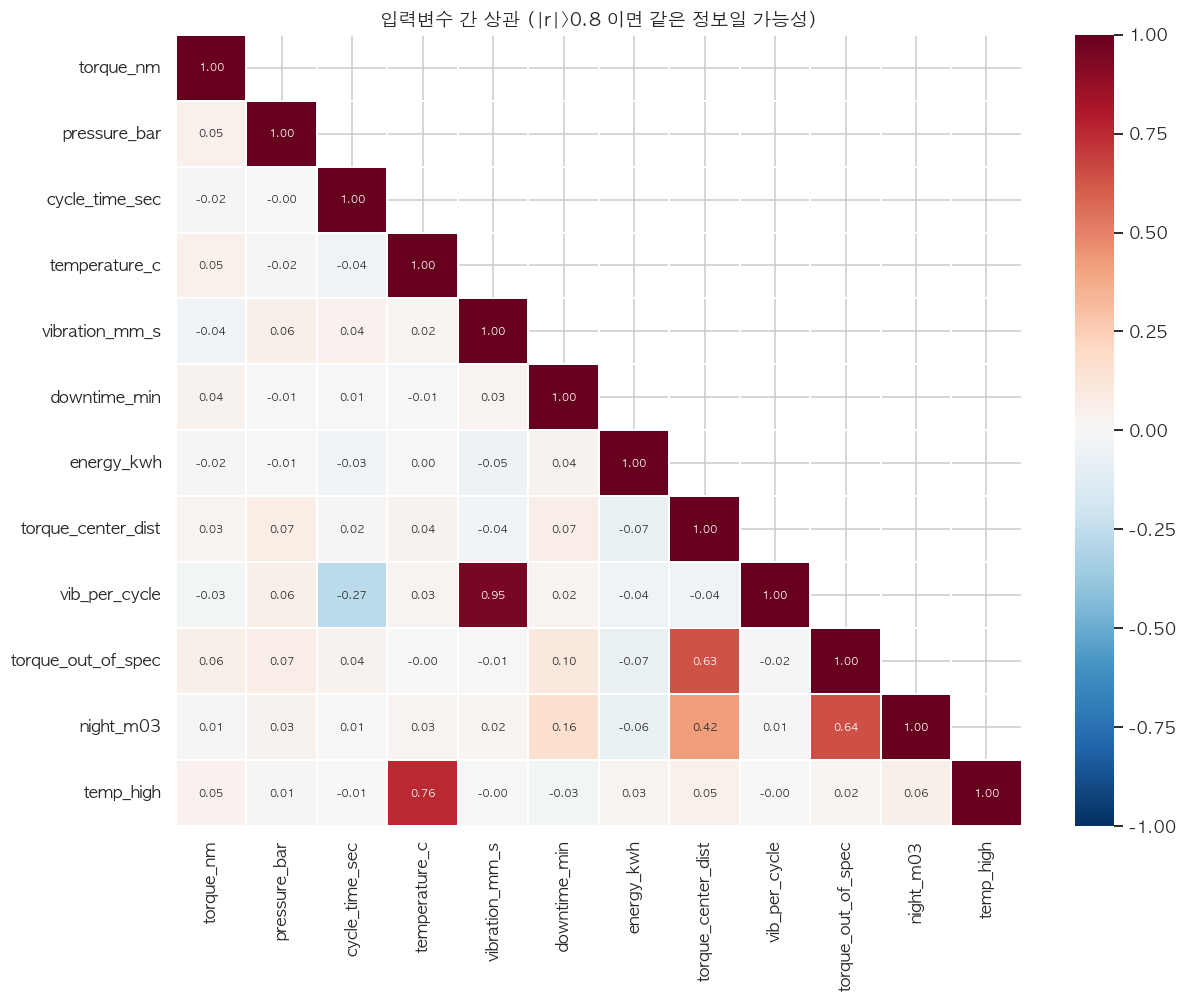

[상관이 0.8 이상인 쌍 - 둘 중 하나를 빼는 것을 검토]


,변수1,변수2,상관계수
0,vibration_mm_s,vib_per_cycle,0.948


In [15]:
# =============================================================================
# [7-1] 수치형 변수 간 상관 + 강한 상관 쌍 찾기
# =============================================================================
num_check = [c for c in NUM_FE if df_fe[c].notna().sum() > 30]
corr = df_fe[num_check].corr()

fig, ax = plt.subplots(figsize=(0.62 * len(num_check) + 4, 0.52 * len(num_check) + 3))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            annot=len(num_check) <= 16, fmt=".2f", annot_kws={"size": 7},
            linewidths=0.3, ax=ax)
ax.set_title("입력변수 간 상관 (|r|>0.8 이면 같은 정보일 가능성)")
plt.tight_layout()
plt.show()

pairs = []
for i in range(len(num_check)):
    for j in range(i + 1, len(num_check)):
        r = corr.iloc[i, j]
        if abs(r) >= 0.8:
            pairs.append({"변수1": num_check[i], "변수2": num_check[j],
                          "상관계수": round(r, 3)})
if pairs:
    print("[상관이 0.8 이상인 쌍 - 둘 중 하나를 빼는 것을 검토]")
    display(pd.DataFrame(pairs).sort_values("상관계수", key=np.abs, ascending=False))
else:
    print("상관이 0.8 이상인 쌍은 없습니다.")

In [16]:
# =============================================================================
# [7-2] VIF(분산팽창계수) 계산 - 외부 패키지 없이 직접 구현
# =============================================================================
from sklearn.linear_model import LinearRegression

vif_data = df_fe[num_check].dropna()
vif_rows = []
for c in num_check:
    y_v = vif_data[c]
    X_v = vif_data.drop(columns=[c])
    if X_v.shape[1] == 0 or y_v.std() == 0:
        continue
    r2 = LinearRegression().fit(X_v, y_v).score(X_v, y_v)   # 나머지로 그 변수를 설명
    vif = 1 / (1 - r2) if r2 < 0.9999 else np.inf
    vif_rows.append({"변수": c, "R²": round(r2, 3), "VIF": round(vif, 2)})

vif_tbl = pd.DataFrame(vif_rows).sort_values("VIF", ascending=False).set_index("변수")
vif_tbl["판정"] = pd.cut(vif_tbl["VIF"], [-np.inf, 5, 10, np.inf],
                         labels=["양호", "주의", "심각"])
display(vif_tbl)
print("VIF가 높은 변수는 '다른 변수들로 거의 완벽히 설명되는 변수'다.")
print("→ 계수 해석이 필요하면 제거를 검토하고, 예측만 할 거면 그대로 둬도 된다.")

,R²,VIF,판정
변수,,,
vib_per_cycle,0.996,245.680,심각
vibration_mm_s,0.996,228.060,심각
cycle_time_sec,0.960,25.130,심각
temp_high,0.580,2.380,양호
temperature_c,0.579,2.370,양호
torque_out_of_spec,0.576,2.360,양호
night_m03,0.426,1.740,양호
torque_center_dist,0.405,1.680,양호
downtime_min,0.034,1.030,양호


VIF가 높은 변수는 '다른 변수들로 거의 완벽히 설명되는 변수'다.
→ 계수 해석이 필요하면 제거를 검토하고, 예측만 할 거면 그대로 둬도 된다.


---

## 8. 특성선택 — 변수를 줄여도 될까?

변수를 줄이는 것은 성능 때문만이 아닙니다. **현장 운영 비용** 때문입니다.

- 센서 20개를 상시 감시하려면 설치·보전 비용이 든다
- 점검표가 20줄이면 아무도 안 본다
- 변수가 적을수록 모델을 설명하기 쉽다
- 변수가 적을수록 **새 데이터에서 더 안정적**인 경우가 많다 (과적합 감소)

### 네 가지 방법

| 방법 | 원리 | 장점 | 단점 |
|---|---|---|---|
| **분산 기준** | 값이 거의 변하지 않는 변수 제거 | 매우 빠름 | 목표변수를 안 봄 |
| **단변량 선택** (`SelectKBest`) | 변수 하나씩 목표와의 관련성 측정 | 빠르고 직관적 | **변수 조합을 못 본다** |
| **모델 기반** (`SelectFromModel`) | 모델의 중요도로 자르기 | 조합 반영 | 모델에 의존 |
| **RFE** (재귀적 제거) | 약한 변수를 하나씩 빼며 재학습 | 가장 정교 | **느림** |

**단변량 선택의 한계**를 꼭 이해하세요. "혼자서는 쓸모없지만 다른 변수와 함께면
강력한 변수"를 버립니다. 제조 데이터에는 그런 변수가 많습니다
(예: 온도 혼자서는 의미 없지만, 부하와 함께 보면 이상 신호).

`f_classif`(F검정)는 **직선 관계**를, `mutual_info_classif`(상호정보량)은
**비선형 관계까지** 잡아냅니다. 둘을 함께 보면 좋습니다.

,변수,F점수,p값,상호정보량,F순위,MI순위
0,torque_out_of_spec,74.817,0.000,0.017,1.000,3.000
1,torque_center_dist,22.890,0.000,0.018,2.000,2.000
2,energy_kwh,12.369,0.001,0.007,3.000,6.000
3,night_m03,8.908,0.003,0.002,4.000,14.000
4,equipment_id_M03,5.049,0.025,0.002,5.000,15.000
5,temperature_c,4.031,0.045,0.000,6.000,23.000
6,temp_high,3.510,0.061,0.002,7.000,16.000
7,operator_group_G06,3.192,0.074,0.014,8.000,4.000
8,equipment_id_M01,2.387,0.123,0.006,9.000,9.000
9,shift_주간,2.213,0.137,0.009,10.000,5.000


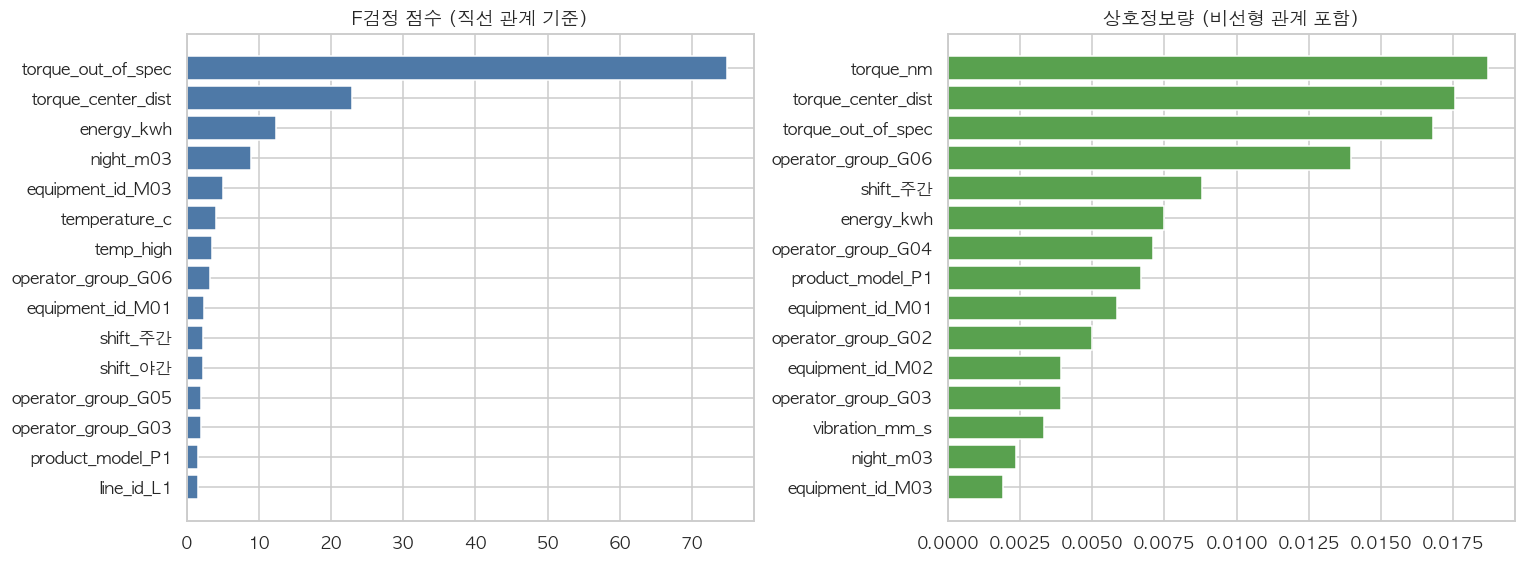

두 방법의 순위가 다르다면, 그 변수는 '직선이 아닌 관계'를 가질 가능성이 있다.
p값 < 0.05 는 '우연이라고 보기 어렵다'는 뜻이지만, 표본이 크면 작은 차이도 유의하게 나온다.


In [17]:
# =============================================================================
# [8-1] 단변량 선택 - F검정과 상호정보량
# =============================================================================
pre_fe = make_preprocessor(CAT_FE, NUM_FE)
Xt = pre_fe.fit_transform(Xf_tr)
names_fe = [n.replace("num__", "").replace("cat__", "")
            for n in pre_fe.get_feature_names_out()]

f_scores, f_pvals = f_classif(Xt, yf_tr)
mi_scores = mutual_info_classif(Xt, yf_tr, random_state=SEED)

uni = pd.DataFrame({"변수": names_fe, "F점수": f_scores, "p값": f_pvals,
                    "상호정보량": mi_scores})
uni["F순위"] = uni["F점수"].rank(ascending=False)
uni["MI순위"] = uni["상호정보량"].rank(ascending=False)
uni = uni.sort_values("F점수", ascending=False).reset_index(drop=True)
display(uni.head(15).round(4))

fig, axes = plt.subplots(1, 2, figsize=(14, max(4, 0.35 * min(15, len(uni)))))
t1 = uni.head(15)[::-1]
axes[0].barh(t1["변수"], t1["F점수"], color="#4e79a7")
axes[0].set_title("F검정 점수 (직선 관계 기준)")
t2 = uni.sort_values("상호정보량", ascending=False).head(15)[::-1]
axes[1].barh(t2["변수"], t2["상호정보량"], color="#59a14f")
axes[1].set_title("상호정보량 (비선형 관계 포함)")
plt.tight_layout()
plt.show()

print("두 방법의 순위가 다르다면, 그 변수는 '직선이 아닌 관계'를 가질 가능성이 있다.")
print("p값 < 0.05 는 '우연이라고 보기 어렵다'는 뜻이지만, 표본이 크면 작은 차이도 유의하게 나온다.")

,변수 수,ROC_AUC,Recall,F1
0,3,0.709,0.000,0.000
1,5,0.905,0.250,0.375
2,8,0.868,0.083,0.133
3,12,0.870,0.250,0.353
4,20,0.902,0.417,0.588
5,28,0.899,0.083,0.154


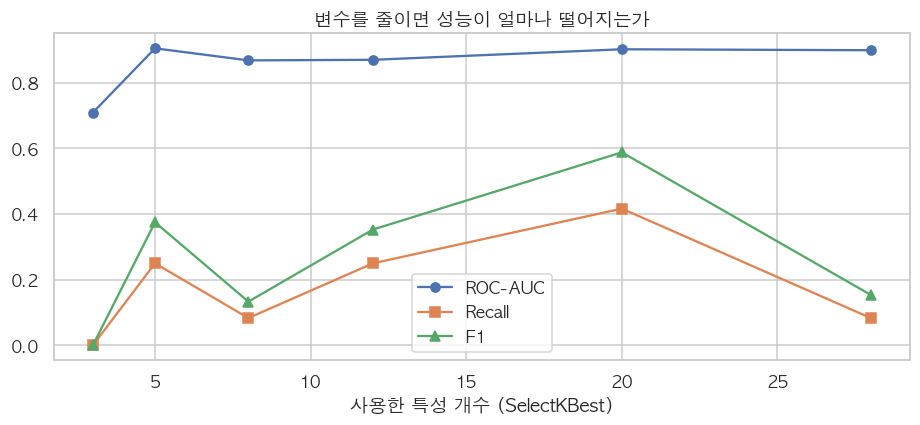

성능이 평평해지는 지점이 '충분한 변수 개수'다.
그 이상은 비용만 늘고 효과가 없다 → 현장 센서 선정의 근거가 된다.


In [18]:
# =============================================================================
# [8-2] 변수 개수에 따른 성능 변화 - 몇 개면 충분한가?
# =============================================================================
ks = [3, 5, 8, 12, 20, min(30, Xt.shape[1]), Xt.shape[1]]
ks = sorted(set(k for k in ks if 0 < k <= Xt.shape[1]))

rows = []
for k in ks:
    pipe = Pipeline([
        ("pre", make_preprocessor(CAT_FE, NUM_FE)),
        ("select", SelectKBest(f_classif, k=k)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                       class_weight="balanced", random_state=SEED,
                                       n_jobs=-1)),
    ]).fit(Xf_tr, yf_tr)
    proba = pipe.predict_proba(Xf_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    rows.append({"변수 수": k,
                 "ROC_AUC": roc_auc_score(yf_te, proba),
                 "Recall": recall_score(yf_te, pred, zero_division=0),
                 "F1": f1_score(yf_te, pred, zero_division=0)})
sel_tbl = pd.DataFrame(rows)
display(sel_tbl.round(3))

fig, ax = plt.subplots(figsize=(8.5, 4))
ax.plot(sel_tbl["변수 수"], sel_tbl["ROC_AUC"], "o-", label="ROC-AUC")
ax.plot(sel_tbl["변수 수"], sel_tbl["Recall"], "s-", label="Recall")
ax.plot(sel_tbl["변수 수"], sel_tbl["F1"], "^-", label="F1")
ax.set_xlabel("사용한 특성 개수 (SelectKBest)")
ax.set_title("변수를 줄이면 성능이 얼마나 떨어지는가")
ax.legend()
plt.tight_layout()
plt.show()

print("성능이 평평해지는 지점이 '충분한 변수 개수'다.")
print("그 이상은 비용만 늘고 효과가 없다 → 현장 센서 선정의 근거가 된다.")

① SelectFromModel 선택: 10개
   ['torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'energy_kwh', 'torque_center_dist', 'vib_per_cycle', 'torque_out_of_spec', 'night_m03']

② RFECV 선택: 28개 (최적 개수 28)
   ['torque_nm', 'pressure_bar', 'cycle_time_sec', 'temperature_c', 'vibration_mm_s', 'downtime_min', 'energy_kwh', 'torque_center_dist', 'vib_per_cycle', 'torque_out_of_spec', 'night_m03', 'temp_high', 'shift_야간', 'shift_주간', 'line_id_L1', 'line_id_L2', 'product_model_P1', 'product_model_P2', 'equipment_id_M01', 'equipment_id_M02', 'equipment_id_M03', 'equipment_id_M04', 'operator_group_G01', 'operator_group_G02', 'operator_group_G03', 'operator_group_G04', 'operator_group_G05', 'operator_group_G06']

③ 두 방법이 공통으로 고른 변수 10개 — 가장 믿을 만한 핵심 변수
   ['cycle_time_sec', 'energy_kwh', 'night_m03', 'pressure_bar', 'temperature_c', 'torque_center_dist', 'torque_nm', 'torque_out_of_spec', 'vib_per_cycle', 'vibration_mm_s']


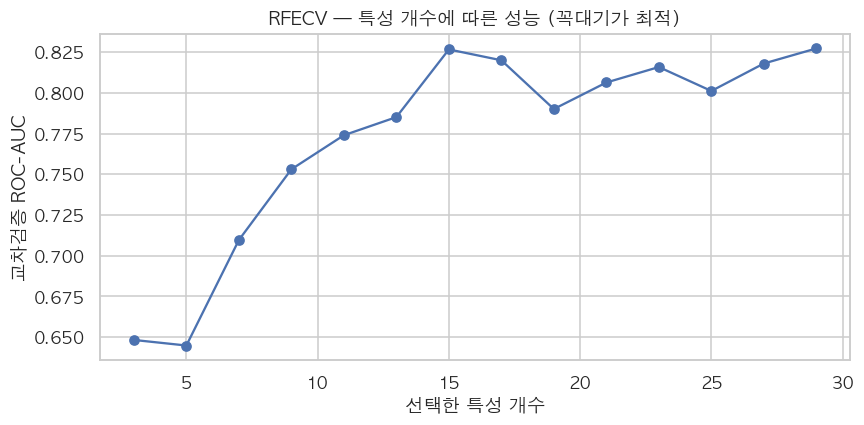

In [19]:
# =============================================================================
# [8-3] 모델 기반 선택(SelectFromModel)과 RFE 비교
# =============================================================================
# ① 모델 기반: 랜덤포레스트 중요도가 평균 이상인 변수만
sfm = SelectFromModel(RandomForestClassifier(n_estimators=200, random_state=SEED,
                                             class_weight="balanced", n_jobs=-1),
                      threshold="mean").fit(Xt, yf_tr)
sfm_sel = [n for n, k in zip(names_fe, sfm.get_support()) if k]

# ② RFE: 약한 변수를 하나씩 제거하며 교차검증 (느리므로 트리 수를 줄인다)
rfe = RFECV(RandomForestClassifier(n_estimators=120, random_state=SEED,
                                   class_weight="balanced", n_jobs=-1),
            step=2, cv=StratifiedKFold(3), scoring="roc_auc",
            min_features_to_select=3, n_jobs=-1).fit(Xt, yf_tr)
rfe_sel = [n for n, k in zip(names_fe, rfe.get_support()) if k]

print(f"① SelectFromModel 선택: {len(sfm_sel)}개")
print("  ", sfm_sel)
print(f"\n② RFECV 선택: {len(rfe_sel)}개 (최적 개수 {rfe.n_features_})")
print("  ", rfe_sel)

common = sorted(set(sfm_sel) & set(rfe_sel))
print(f"\n③ 두 방법이 공통으로 고른 변수 {len(common)}개 — 가장 믿을 만한 핵심 변수")
print("  ", common)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(rfe.cv_results_["n_features"], rfe.cv_results_["mean_test_score"], "o-")
ax.set_xlabel("선택한 특성 개수")
ax.set_ylabel("교차검증 ROC-AUC")
ax.set_title("RFECV — 특성 개수에 따른 성능 (꼭대기가 최적)")
plt.tight_layout()
plt.show()

---

## 9. PCA — 변수를 '압축'하기

### PCA(주성분분석)란

변수가 20개라도 실제로는 **서로 겹치는 정보**가 많습니다. PCA는 이 겹침을 이용해
**정보 손실을 최소화하면서 변수 개수를 줄이는** 방법입니다.

직관적으로 설명하면 이렇습니다.

> 데이터가 가장 **넓게 퍼진 방향**을 찾아 그것을 새 축(제1주성분)으로 삼는다.
> 그 다음, 첫 축과 **직각이면서** 가장 넓게 퍼진 방향을 제2주성분으로 삼는다. 반복.

압축사진과 같습니다. 용량(변수 수)을 줄이되 그림(정보)은 최대한 지킵니다.

### 반드시 지켜야 할 두 가지

1. **반드시 표준화 먼저!** PCA는 "분산이 큰 방향"을 찾으므로, 단위가 큰 변수가
   무조건 1등 주성분이 됩니다. (운전시간 0~475 vs 압력 5.6~6.0)
2. **주성분은 해석이 어렵습니다.** PC1은 "온도 0.4 + 진동 0.3 + 전류 0.5 − ..."
   같은 **섞인 축**입니다. 현장에 "PC1이 2.3을 넘으면 점검하세요"라고 말하기 어렵습니다.

### 그래서 PCA는 언제 쓰는가

| 쓰면 좋을 때 | 쓰지 말아야 할 때 |
|---|---|
| 변수가 매우 많고 서로 강하게 상관될 때 | **어떤 변수가 중요한지 설명해야 할 때** |
| 2차원으로 **시각화**해서 군집을 보고 싶을 때 | 변수가 10~20개 수준일 때(효과 작음) |
| 다중공선성이 심해 계수가 불안정할 때 | 트리 계열 모델을 쓸 때(이미 잘 처리함) |

제조 현장 프로젝트에서는 **시각화와 탐색 용도**로 쓰고,
최종 모델은 원래 변수로 만드는 경우가 많습니다. 설명해야 하기 때문입니다.

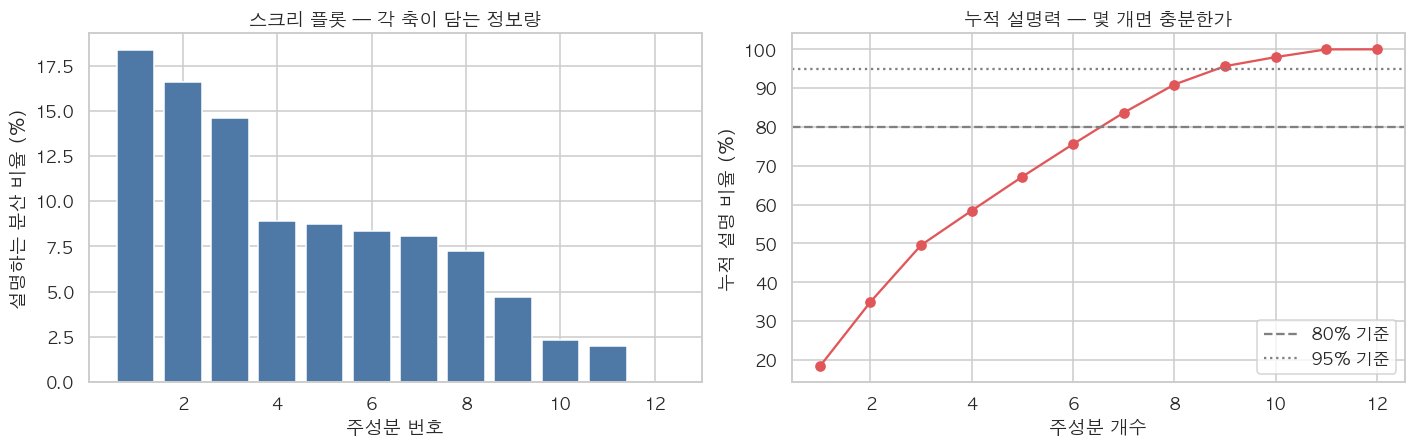

원래 변수 12개 중
  주성분 7개로 정보의 80%를 담을 수 있다
  주성분 9개로 정보의 95%를 담을 수 있다
  PC1 단독 설명력: 18.4%, PC2: 16.6%


In [20]:
# =============================================================================
# [9-1] PCA - 몇 개 축으로 정보를 얼마나 담을 수 있나 (스크리 플롯)
# =============================================================================
pca_num = [c for c in NUM_FE if df_fe[c].notna().sum() > 30]
X_pca_raw = df_fe[pca_num].copy()
X_pca_raw = X_pca_raw.fillna(X_pca_raw.median())
X_std = StandardScaler().fit_transform(X_pca_raw)     # ① 반드시 표준화

pca = PCA().fit(X_std)
evr = pca.explained_variance_ratio_
cum = np.cumsum(evr)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].bar(range(1, len(evr) + 1), evr * 100, color="#4e79a7")
axes[0].set_xlabel("주성분 번호")
axes[0].set_ylabel("설명하는 분산 비율 (%)")
axes[0].set_title("스크리 플롯 — 각 축이 담는 정보량")

axes[1].plot(range(1, len(cum) + 1), cum * 100, "o-", color="#e15759")
axes[1].axhline(80, color="gray", ls="--", label="80% 기준")
axes[1].axhline(95, color="gray", ls=":", label="95% 기준")
axes[1].set_xlabel("주성분 개수")
axes[1].set_ylabel("누적 설명 비율 (%)")
axes[1].set_title("누적 설명력 — 몇 개면 충분한가")
axes[1].legend()
plt.tight_layout()
plt.show()

n80 = int(np.argmax(cum >= 0.8) + 1)
n95 = int(np.argmax(cum >= 0.95) + 1)
print(f"원래 변수 {len(pca_num)}개 중")
print(f"  주성분 {n80}개로 정보의 80%를 담을 수 있다")
print(f"  주성분 {n95}개로 정보의 95%를 담을 수 있다")
print(f"  PC1 단독 설명력: {evr[0]*100:.1f}%, PC2: {evr[1]*100:.1f}%")

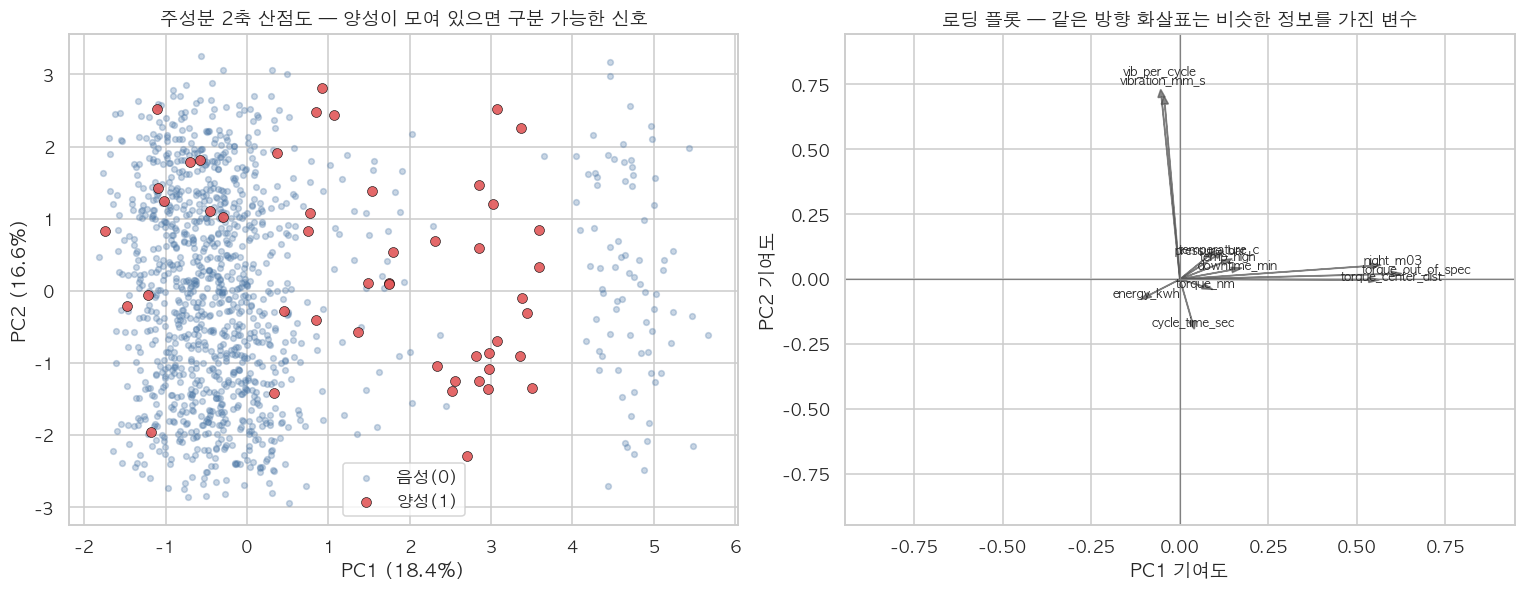

[PC1에 크게 기여하는 변수]
torque_out_of_spec   0.597
night_m03            0.538
torque_center_dist   0.533
downtime_min         0.146
temp_high            0.121
temperature_c        0.100

[PC2에 크게 기여하는 변수]
vib_per_cycle     0.700
vibration_mm_s    0.674
cycle_time_sec   -0.162
temperature_c     0.088
pressure_bar      0.087
temp_high         0.065

→ PC1이 무엇을 뜻하는지 현장 언어로 이름 붙여 보세요 (예: '전체 부하 수준').


In [21]:
# =============================================================================
# [9-2] PC1-PC2 산점도 - 양성 사례가 특정 영역에 모이는가?
# =============================================================================
pca2 = PCA(n_components=2, random_state=SEED)
pcs = pca2.fit_transform(X_std)
y_pca = df_fe["target"].values

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
axes[0].scatter(pcs[y_pca == 0, 0], pcs[y_pca == 0, 1], s=14, alpha=0.3,
                c="#4e79a7", label="음성(0)")
axes[0].scatter(pcs[y_pca == 1, 0], pcs[y_pca == 1, 1], s=42, alpha=0.9,
                c="#e15759", edgecolors="black", linewidths=0.4, label="양성(1)")
axes[0].set_xlabel(f"PC1 ({evr[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({evr[1]*100:.1f}%)")
axes[0].set_title("주성분 2축 산점도 — 양성이 모여 있으면 구분 가능한 신호")
axes[0].legend()

# 로딩(loading): 각 원래 변수가 PC1, PC2에 기여하는 정도
load = pd.DataFrame(pca2.components_.T, columns=["PC1", "PC2"], index=pca_num)
for v in load.index:
    axes[1].arrow(0, 0, load.loc[v, "PC1"], load.loc[v, "PC2"],
                  head_width=0.02, color="#555", alpha=0.7)
    axes[1].text(load.loc[v, "PC1"] * 1.12, load.loc[v, "PC2"] * 1.12, v,
                 fontsize=8, ha="center")
lim = np.abs(load.values).max() * 1.35
axes[1].set_xlim(-lim, lim)
axes[1].set_ylim(-lim, lim)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].axvline(0, color="gray", lw=0.8)
axes[1].set_xlabel("PC1 기여도")
axes[1].set_ylabel("PC2 기여도")
axes[1].set_title("로딩 플롯 — 같은 방향 화살표는 비슷한 정보를 가진 변수")
plt.tight_layout()
plt.show()

print("[PC1에 크게 기여하는 변수]")
print(load["PC1"].sort_values(key=np.abs, ascending=False).head(6).round(3).to_string())
print("\n[PC2에 크게 기여하는 변수]")
print(load["PC2"].sort_values(key=np.abs, ascending=False).head(6).round(3).to_string())
print("\n→ PC1이 무엇을 뜻하는지 현장 언어로 이름 붙여 보세요 (예: '전체 부하 수준').")

In [22]:
# =============================================================================
# [9-3] PCA를 모델에 써 보기 - 성능과 해석성의 맞바꿈
# =============================================================================
pca_rows = []
for n_comp in [2, 5, min(10, len(pca_num)), len(pca_num)]:
    if n_comp > len(pca_num):
        continue
    pipe = Pipeline([
        ("impute", SimpleImputer(strategy="median")),
        ("scale", StandardScaler()),
        ("pca", PCA(n_components=n_comp, random_state=SEED)),
        ("clf", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                       class_weight="balanced", random_state=SEED,
                                       n_jobs=-1)),
    ])
    Xn_tr, Xn_te = Xf_tr[pca_num], Xf_te[pca_num]
    pipe.fit(Xn_tr, yf_tr)
    proba = pipe.predict_proba(Xn_te)[:, 1]
    pred = (proba >= 0.5).astype(int)
    pca_rows.append({"주성분 수": n_comp,
                     "ROC_AUC": roc_auc_score(yf_te, proba),
                     "Recall": recall_score(yf_te, pred, zero_division=0),
                     "F1": f1_score(yf_te, pred, zero_division=0)})

# 비교군: PCA 없이 원래 수치형 변수만 사용
plain = Pipeline([
    ("impute", SimpleImputer(strategy="median")),
    ("scale", StandardScaler()),
    ("clf", RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                   class_weight="balanced", random_state=SEED, n_jobs=-1)),
]).fit(Xf_tr[pca_num], yf_tr)
pp = plain.predict_proba(Xf_te[pca_num])[:, 1]
pca_rows.append({"주성분 수": "PCA 없음(원본)",
                 "ROC_AUC": roc_auc_score(yf_te, pp),
                 "Recall": recall_score(yf_te, (pp >= 0.5).astype(int), zero_division=0),
                 "F1": f1_score(yf_te, (pp >= 0.5).astype(int), zero_division=0)})

display(pd.DataFrame(pca_rows).set_index("주성분 수").round(3))
print("PCA로 성능이 크게 떨어지지 않는다면 '정보가 몇 개 축에 모여 있다'는 뜻이다.")
print("그래도 최종 모델은 원래 변수로 만드는 경우가 많다. 현장에 설명해야 하기 때문이다.")

,ROC_AUC,Recall,F1
주성분 수,,,
2,0.822,0.500,0.343
5,0.832,0.417,0.385
10,0.861,0.417,0.526
12,0.854,0.333,0.471
PCA 없음(원본),0.844,0.167,0.286


PCA로 성능이 크게 떨어지지 않는다면 '정보가 몇 개 축에 모여 있다'는 뜻이다.
그래도 최종 모델은 원래 변수로 만드는 경우가 많다. 현장에 설명해야 하기 때문이다.


---

## 10. 3편 정리 — 최종 특성 세트 제안

### 오늘 배운 것

| 주제 | 핵심 |
|---|---|
| 계수(가중치) | 부호=방향, 크기=영향력(표준화 후), exp(계수)=오즈비 |
| 특성중요도 | 트리가 얼마나 많이 썼나. 고유값 많은 변수를 과대평가 |
| 순열 중요도 | 변수를 망가뜨리면 성능이 얼마나 떨어지나. **모델 무관, 평가셋 기준** |
| 특성공학 | **도메인 지식 → 숫자**. 성능 향상 효과가 가장 크다 |
| 다중공선성 | 같은 말을 하는 변수. 예측엔 무해, **해석엔 치명적** |
| 특성선택 | 변수 축소 = 센서 비용·설명력·안정성 |
| PCA | 압축·시각화에는 좋지만 **해석이 어렵다** |

### 캡스톤 제출물로 정리할 내용

1. **핵심 변수 Top 5** — 세 가지 방법 모두에서 상위권인 변수
2. **만든 파생변수와 그 근거** — "왜 이 계산식이 현장 의미를 갖는가"
3. **제거한 변수와 그 이유** — 누출 / 다중공선성 / 중요도 낮음
4. **최종 특성 세트** — 모델에 쓸 변수 목록(이후 Blind Test까지 **변경 금지**)
5. **현장 적용안** — "상시 감시할 지표 N개"와 점검 기준

> **중요**: 10~11회차에서 **방법론 동결(freeze)** 을 합니다.
> 그 이후에는 전처리 규칙·특성·모델·임계값을 바꾸지 않고 Blind 데이터에 적용합니다.
> 지금 정리해 둔 내용이 그대로 동결 대상이 됩니다.

In [23]:
# =============================================================================
# [10-1] 최종 요약 - 세 가지 방법의 종합 순위
# =============================================================================
final_rank = cmp3.copy()
rank_cols = [c for c in final_rank.columns if c.endswith("순위")]
final_rank["종합순위점수"] = final_rank[rank_cols].mean(axis=1)
final_rank = final_rank.sort_values("종합순위점수")
display(final_rank[rank_cols + ["종합순위점수"]].round(2).head(10))

print("=" * 70)
print("[핵심 변수 Top 5 - 발표자료에 쓸 목록]")
for i, v in enumerate(final_rank.index[:5], 1):
    print(f"  {i}. {v}")
print()
print("[이번 노트북에서 만든 파생변수]")
for v in NEW_NUM + NEW_CAT:
    print(f"  - {v}")
print()
print("[제외한 변수 - 데이터 누출]")
for v in LEAK_COLS:
    print(f"  - {v}")
print("=" * 70)

,로지스틱 |계수| 순위,RF 특성중요도 순위,순열 중요도 순위,종합순위점수
equipment_id,2.000,5.000,1.000,2.670
torque_nm,10.000,1.000,2.000,4.330
cycle_time_sec,5.000,4.000,5.000,4.670
energy_kwh,3.000,2.000,10.000,5.000
shift,6.000,9.000,3.000,6.000
operator_group,1.000,8.000,9.000,6.000
temperature_c,4.000,3.000,12.000,6.330
line_id,7.500,10.000,4.000,7.170
product_model,7.500,11.000,7.000,8.500
vibration_mm_s,12.000,6.000,8.000,8.670


[핵심 변수 Top 5 - 발표자료에 쓸 목록]
  1. equipment_id
  2. torque_nm
  3. cycle_time_sec
  4. energy_kwh
  5. shift

[이번 노트북에서 만든 파생변수]
  - torque_center_dist
  - vib_per_cycle
  - torque_out_of_spec
  - night_m03
  - temp_high

[제외한 변수 - 데이터 누출]
  - defect_type
  - inspection_time_sec
  - rework_flag
  - rework_time_min
  - final_disposition
  - record_id


---

## 연습문제 / 생각해 볼 질문

아래 문항은 정답을 맞히는 시험이 아니라, **발표자료에 쓸 문장을 만드는 연습**입니다.
코드를 조금씩 바꿔 보고, 결과를 한 문장으로 정리해 보세요.

1. 로지스틱 회귀 계수 상위 5개와 랜덤포레스트 특성중요도 상위 5개를 비교해, 두 결과가 다른 이유를 설명하세요.
2. `line_id` 를 제외하고 다시 학습해 보세요. 성능은 얼마나 바뀌고, 계수 해석은 어떻게 쉬워집니까?
3. `add_features()` 에 본인이 생각한 파생변수를 1개 추가하고(예: 주간 M03 플래그, 토크 규격이탈 × 제품모델), 성능과 중요도 변화를 확인하세요.
4. PCA 1~2축 산점도에서 불합격 제품이 뚜렷하게 모여 있나요? 모여 있지 않다면 그 사실 자체가 알려 주는 것은 무엇입니까?
5. `SelectKBest(k=5)` 로 고른 변수만으로 랜덤포레스트를 학습해 성능을 비교하고, '센서 5개만 상시 감시한다면 무엇을 고를지' 제안하세요.

> 연습문제의 답을 모으면 캡스톤 중간발표의 **분석 방법론** 장이 됩니다.
> 숫자(성능 변화, 변수 개수)와 함께 **"그래서 현장에서 무엇을 하면 되는가"** 를
> 한 문장으로 쓰는 연습을 하세요.

---

## 1~6회차를 마치며

세 권의 노트북에서 한 일을 한 문장으로 정리하면 이렇습니다.

> **현장 문제를 데이터 질문으로 바꾸고(1편), 판단 시점에 쓸 수 있는 정보로
> 모델을 만들어 비용 관점에서 평가하고(2편), 모델이 무엇을 보고 판단했는지 설명하며
> 변수를 다듬었다(3편).**

### 다음 단계 (7회차 이후)

| 회차 | 내용 |
|---|---|
| 7~9 | 통계검증, 모델 설계 고도화, 이상 시나리오 정의 |
| 10~11 | AI 확장데이터 생성, Self Validation, **방법론 동결** |
| 12~14 | **Blind Test**, 실패분석, 대시보드·Pilot 설계 |
| 15~16 | 결과물 통합, 리허설, 최종 발표 |

**Blind Test에서 성능이 떨어지는 것은 실패가 아닙니다.**
왜 떨어졌는지, 어떤 유형을 놓쳤는지 설명할 수 있다면 그것이 더 좋은 결과입니다.
현장에 적용된 모델은 모두 그 과정을 거칩니다.

---

*공통 미니 프로젝트 (1~2회차 · 4개 팀 동일 데이터) · EOL 최종검사 불량 선별 · K-뉴딜 아카데미 스마트팩토리 캡스톤*